In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("duplicated rows:")
print(df.duplicated().sum())

print("missing values: \n")
print(df.isnull().sum())

print("data type: \n")
print(df.dtypes)


duplicated rows:
0
missing values: 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
data type: 

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str

In [6]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})


In [7]:
print(df["Churn"].value_counts())
print(df["Churn"].isnull().sum())


Churn
0    5174
1    1869
Name: count, dtype: int64
0


In [8]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)


Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


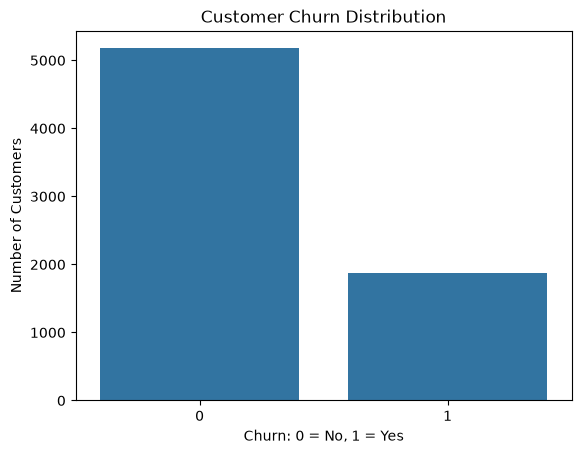

In [9]:

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn: 0 = No, 1 = Yes")
plt.ylabel("Number of Customers")
plt.show()




In [10]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract)


Churn                   0          1
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


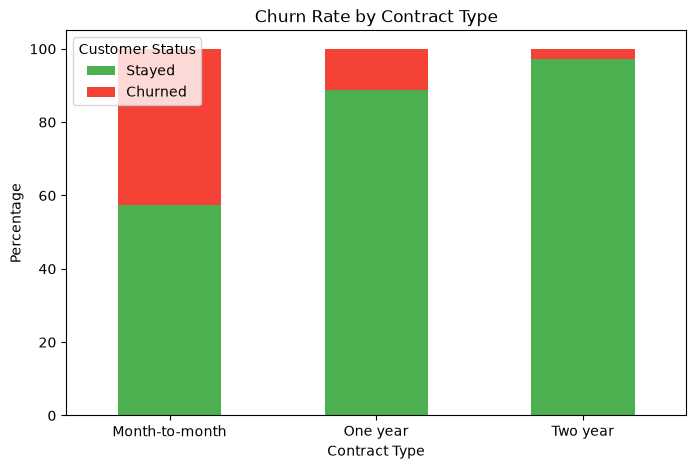

In [11]:
churn_by_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#4CAF50", "#F44336"]
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")
plt.legend(["Stayed", "Churned"], title="Customer Status")
plt.xticks(rotation=0)
plt.show()


so we conclued from the previous chart that the higher the level of contract, the lower the churn rate.

In [12]:
df["tenure"].describe()


count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [13]:
bins = [0, 12, 24, 48, float("inf")]
labels = ["0-12", "13-24", "25-48", "49+"]

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels
)



In [14]:
print(df[["tenure", "tenure_group"]].head(10))


   tenure tenure_group
0       1         0-12
1      34        25-48
2       2         0-12
3      45        25-48
4       2         0-12
5       8         0-12
6      22        13-24
7      10         0-12
8      28        25-48
9      62          49+


In [15]:
print(df["tenure_group"].value_counts().sort_index())


tenure_group
0-12     2175
13-24    1024
25-48    1594
49+      2239
Name: count, dtype: int64


In [16]:
churn_by_tenure = pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100
print(churn_by_tenure)

Churn                 0          1
tenure_group                      
0-12          52.321839  47.678161
13-24         71.289062  28.710938
25-48         79.611041  20.388959
49+           90.486824   9.513176


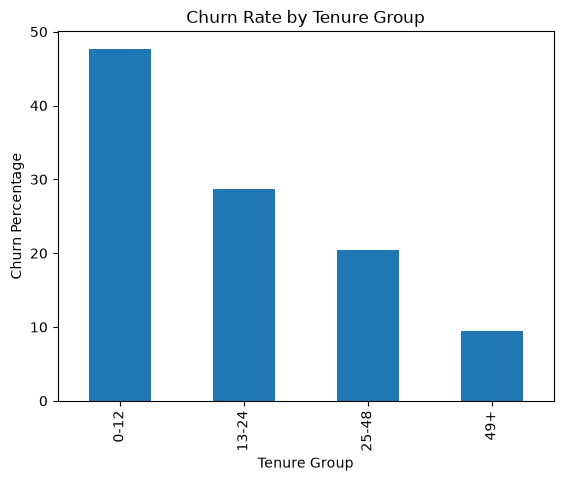

In [17]:
churn_by_tenure[1].plot(
    kind='bar'

)
plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Percentage")
plt.show()


In [18]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100
print(payment_churn)

Churn                              0          1
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


So Electronic check has the higher percent of churn

In [19]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100
print(internet_churn)


Churn                    0          1
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


fiber has the higher percent of churn

In [20]:
df.drop(columns=["customerID"])

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.5,0,25-48
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0,13-24
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0,49+
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0,0-12
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,1,0-12


In [63]:
X = df.drop(columns=["Churn" , "customerID" ])
y = df["Churn"]


In [64]:
print(X.shape)
print(y.shape)


(7043, 20)
(7043,)


In [23]:
print(X.iloc[0])
print(y.iloc[0])


gender                        Female
SeniorCitizen                      0
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
MultipleLines       No phone service
InternetService                  DSL
OnlineSecurity                    No
OnlineBackup                     Yes
DeviceProtection                  No
TechSupport                       No
StreamingTV                       No
StreamingMovies                   No
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
tenure_group                    0-12
Name: 0, dtype: object
0


In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [62]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)


In [26]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training target distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [39]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(df["TotalCharges"].isna().sum())
print(df["TotalCharges"].dtype)


0
float64


In [45]:
print(df["tenure_group"].value_counts(dropna=False))


tenure_group
49+      2239
0-12     2175
25-48    1594
13-24    1024
NaN        11
Name: count, dtype: int64


In [59]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtype)

float64


In [46]:
most_common_group = df["tenure_group"].mode()[0]

df["tenure_group"] = df["tenure_group"].fillna(
    most_common_group
)

print(df["tenure_group"].isna().sum())


0


In [66]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["str", "object", "category"]
).columns

print("Numeric columns:")
print(numeric_features.tolist())

print("\nCategorical columns:")
print(categorical_features.tolist())



Numeric columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)


In [68]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


In [69]:
print("Before processing:", X_train.shape)
print("After processing:", X_train_processed.shape)


Before processing: (5634, 20)
After processing: (5634, 49)


In [70]:
import numpy as np
from scipy import sparse

if sparse.issparse(X_train_processed):
    X_train_processed = X_train_processed.tocsr()
    X_test_processed = X_test_processed.tocsr()
    
    X_train_processed.data = np.nan_to_num(
        X_train_processed.data,
        nan=0.0
    )
    
    X_test_processed.data = np.nan_to_num(
        X_test_processed.data,
        nan=0.0
    )
else:
    X_train_processed = np.nan_to_num(
        X_train_processed,
        nan=0.0
    )
    
    X_test_processed = np.nan_to_num(
        X_test_processed,
        nan=0.0
    )


In [71]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)


In [72]:
logistic_model.fit(
    X_train_processed,
    y_train
)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [73]:
y_logistic_pred = logistic_model.predict(X_test_processed)


In [74]:
print(y_logistic_pred.shape)


(1409,)


In [84]:
from sklearn.metrics import accuracy_score, recall_score, f1_score , classification_report , precision_score

print("Accuracy:", accuracy_score(y_test, y_logistic_pred))
print("Recall:", recall_score(y_test, y_logistic_pred))
print("F1-score:", f1_score(y_test, y_logistic_pred))
print("Precision:", precision_score(y_test,  y_logistic_pred))


Accuracy: 0.7338537970191625
Recall: 0.7941176470588235
F1-score: 0.6130030959752322
Precision: 0.4991596638655462


Logistic Regression Results 
Accuracy: 0.732
Recall: 0.791
F1-score: 0.611

In [76]:

print(df.isna().sum().sort_values(ascending=False))



customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
tenure_group        0
dtype: int64


In [77]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(   
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    criterion="gini",
    random_state=42)


decision_tree = decision_tree.fit( X_train_processed,
    y_train)


In [78]:
d_y_pred = decision_tree.predict(X_test_processed)

In [79]:
print(d_y_pred.shape)

(1409,)


In [83]:
print("Accuracy:", accuracy_score(y_test, d_y_pred))
print("Recall:", recall_score(y_test, d_y_pred))
print("F1-score:", f1_score(y_test, d_y_pred))
print("Precision:", precision_score(y_test, d_y_pred))

Accuracy: 0.7551454932576295
Recall: 0.7566844919786097
F1-score: 0.6212952799121844
Precision: 0.527001862197393


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]
 


0


In [86]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)


print("Random Forest Results")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")


print("\nClassification Report:")
print(classification_report(y_test, rf_pred))



Random Forest Results
Accuracy:  0.7594
Precision: 0.5316
Recall:    0.7861
F1-score:  0.6343

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1035
           1       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [87]:
from xgboost import XGBClassifier

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("scale_pos_weight:", scale_pos_weight)


scale_pos_weight: 2.768561872909699


In [88]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

xgb_pred = xgb_model.predict(X_test_processed)
xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]


In [89]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)

print("XGBoost Results")
print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-score:  {xgb_f1:.4f}")


print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))



XGBoost Results
Accuracy:  0.7594
Precision: 0.5319
Recall:    0.7807
F1-score:  0.6327

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [92]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        0.7324,
        0.7551,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        0.4991,
        0.5270,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        0.7914,
        0.7567,
        rf_recall,
        xgb_recall
    ],
    "F1-score": [
        0.6109,
        0.6213,
        rf_f1,
        xgb_f1
    ]
})

results


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.732400,0.499100,0.791400,0.610900
1,Decision Tree,0.755100,0.527000,0.756700,0.621300
2,Random Forest,0.759404,0.531646,0.786096,0.634304
3,XGBoost,0.759404,0.531876,0.780749,0.632719


C:\Users\abdul\AppData\Local\Temp\ipykernel_7660\3811959514.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\abdul\AppData\Local\Temp\ipykernel_7660\3811959514.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\abdul\AppData\Local\Temp\ipykernel_7660\3811959514.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\abdul\AppData\Local\Temp\ipykernel_7660\3811959514.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and 

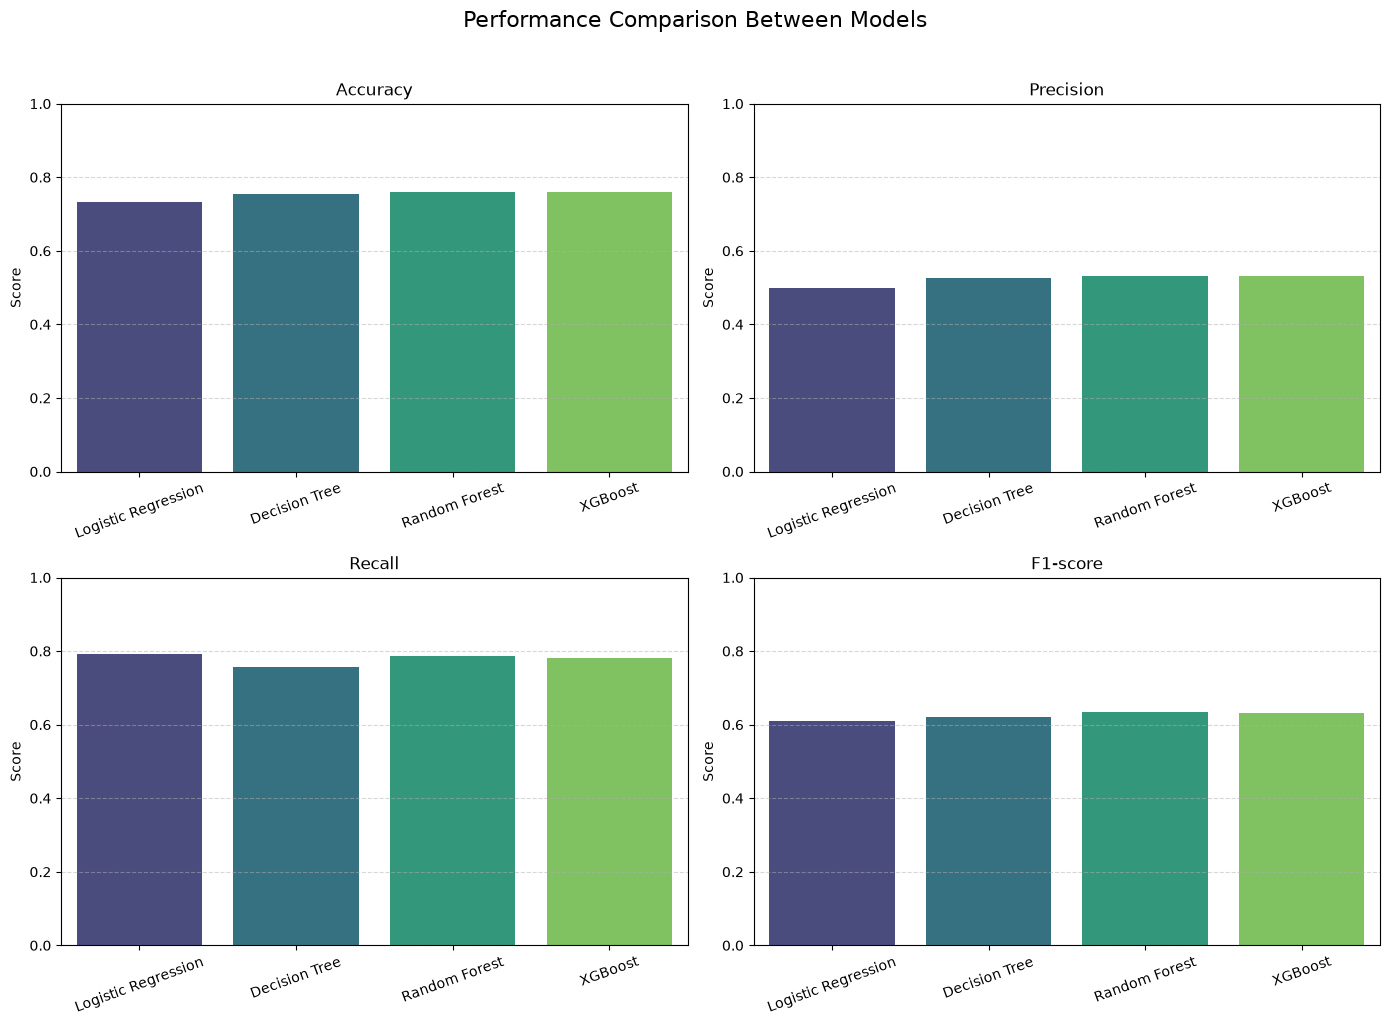

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for ax, metric in zip(axes.flatten(), metrics):
    sns.barplot(
        data=results,
        x="Model",
        y=metric,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle(
    "Performance Comparison Between Models",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()



